<a href="https://colab.research.google.com/github/js-DigitalSurfer/ML/blob/main/Wyk%C5%82ad3_ROC_kros_walidacja.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#!pip install --upgrade pip

In [ ]:
#!pip install seaborn
#!pip install imbalanced-learn

# Powtórka
* Jaką hipotezę wybraliśmy dla regresji logistycznej?

$\qquad$ $h_\theta(x) = g(\theta^T x) =  \frac{1}{1+ \exp(-\theta^T x)}$

* Co to jest funkcja wiarygodności?

_Funkcja wiarygodności to prawdopodobieństwo zaobserwowania ciągu uczącego w zależności od przyjętego $\theta$._
$\qquad$$L(\theta ) = L(\theta ;X,\mathbf {y}) = p(\mathbf {y}|X;\theta )$

*  Na czym polega "Zasada największej wiarygodności"?

**Dobre parametry $\theta$ to te, dla których zaobserwowanie ciągu uczącego jest największe.** Aby je znaleźć należy zmaksymalizować funkcję wiarygodności, czy też dowolną monotonicznie rosnącą funkcję funkcji wiarygodności np. log-wiarygodność.

* Jak pokazać, że dany rozkład należy do rodziny rozkładów wykładniczych?


$\qquad$$ p(y;\eta) = b(y) \exp(\eta^T T(y) - a(\eta))$

* Jak znaleźć hipotezę dla danych modelowanych przez pewien znany rozkład w oparciu o GLM?

> Postulujemy, że hipoteza ma postać:
>$\qquad$ $h(x)= E[T(y)|x]$
>* często $T(y) = y$, wtedy  $h(x)= E[y|x]$
>* Parametr naturalny $\eta$ jest **liniowo związany z wejściem** $x$: $\qquad$$\eta = \theta^T x$.

* Jak wygląda funkcją softmax i gdzie jej używamy?

$\qquad$$\phi_i = \frac{\exp(\eta_i)}{\sum_{j=1}^k \exp(\eta_j)}$

# Ocena klasyfikatorów binarnych

* Klasyfikatory binarne to te, których zadaniem jest przypisanie danemu przykładowi jednej z dwóch możliwych klas.
* Przykładem takiego klasyfikatora jest znana już nam regresja logistyczna.

## Przykład klasyfikowania osób na zdrowe i chore na podstawie objawów.

* Klasyfikator jako cechy przyjmuje na wejściu objawy (przedstawione w postaci numerycznej) i zwraca wynik klasyfikacji (testu).

* Zakładamy, że mamy dane zawierające zarówno objawy $O$ jak i faktyczny stan osoby $S$ dla pewnej grupy osób
 * $S$ może mieć dwie wartości:
   * zdrowy,
   * chory.
   

* Mamy też pewien klasyfikator, który realizuje odwzorowanie:

$\qquad$ $H(O)  \rightarrow K $

* I tu podobnie, wynik klasyfikatora $K$ może przyjąć jedną z dwóch wartości: zdrowy lub chory.
* W praktyce medycznej najczęściej mówimy, że pozytywny wynik testu wskazuje na chorobę.

## Typy błędów
Porównując stan faktyczny $S$ i klasyfikację $K$ możemy mieć cztery sytuacje. Opisuje je **macierz pomyłek**


<img src="https://www.fuw.edu.pl/~jarekz/WYKLADY/UM/W3_ROC/ROC_table.png"  height=800 width=1200>

Anglojęzyczna nomenklatura często stosowana do opisu tych możliwości to:
* TP: true positive,  hit
* TN: true negative,  correct rejection
* FP: false positive, false alarm, Type I error
* FN: false negative, miss, Type II error

## Miary
* Jeśli mamy zbiór uczący o pewnej liczebności to dla każdego z elementów zbioru uczącego zachodzi jedna z powyżej opisanych możliwości.
* Dla całego zbioru uczącego mamy konkretne liczby przypadków każdego typu.
* Zliczenia tych przypadków są podstawą do stworzenia pewnych miar pozwalających na ocenę klasyfikatora.


### Czułość i specyficzność
* czułość (ang. sensitivity): Prawdopodobieństwo, że klasyfikacja będzie poprawna pod warunkiem, że przypadek jest pozytywny (ang. True Positive Rate, recall).

$\qquad$ $TPR = \frac{TP}{ P} = \frac{TP} { TP+FN}$
 > Prawdopodobieństwo, że test wykonany dla osoby chorej wykaże, że jest ona chora.

* swoistość, specyficzność (ang. specificity, SPC): Prawdopodobieństwo, że klasyfikacja będzie poprawna, pod warunkiem, że przypadek jest negatywny (ang. True Negative Rate, TNR).
  
$\qquad$ $SPC= TNR = \frac{TN}{  N} = \frac{TN} { FP + TN} = 1 - FPR $
 > Prawdopodobieństwo, że dla osoby zdrowej test nie wykryje choroby.

### Fałszywe alarmy
* częstość fałszywych alarmów:  (False Positive Rate)
 > Jak dużej frakcji osób zdrowych test wyjdzie pozytywnie?
>
$\qquad$ $FPR = \frac{FP}{ N} = \frac{FP}{ FP + TN} = 1-SPC = 1-TNR$
* częstość fałszywych odkryć: (False Discovery Rate (FDR)):
 > Jak duża frakcja spośród pozytywnych wyników testu jest fałszywa?
>
$\qquad$ $FDR = \frac{FP}{P'}=\frac{FP}{ FP + TP}$

### Własności predykcyjne: Precyzja
* precyzja pozytywna: (positive predictive value (PPV), precision). Odpowiada na pytanie:
 > Jeśli wynik testu jest pozytywny, jakie jest prawdopodobieństwo, że osoba badana jest chora?
>
$\qquad$ $PPV = \frac{TP}{P'}=\frac{TP}{ TP + FP}$

* precyzja negatywna: (negative predictive value (NPV).) Odpowiada na pytanie:
 > Jeśli wynik testu jest negatywny, jakie jest prawdopodobieństwo, że osoba badana jest zdrowa?
>
$\qquad$ $NPV =\frac{TN }{N'} =\frac{TN }{ TN + FN}$

####  Efekt częstości występowania
Częstość występowania ma znaczący wpływ na opisane powyżej wartości predykcyjne.
* Przypuśćmy, że mamy test na pewną chorobę i charakteryzuje się on 99% czułością i 99% specyficznością.
* Załóżmy, że testowanych jest 2000 osób  i częstość występowania choroby (w próbie) wynosi 50%,
  * to znaczy 1000 z nich są chore a 1000 z nich są zdrowe.
* W takiej sytuacji spodziewamy się  około 990 wyników TP i  990 TN oraz około 10 wyników FP i 10 FN.
* Dodatnie (PPV = 99%) i ujemne (NPV = 99%) wartości predykcyjne są duże, więc możemy mieć wysokie zaufanie do wyniku.

* Jednakże, w przypadku gdy częstość występowania choroby będzie wynosiła  tylko 5%,
  * czyli z 2000 osób tylko 100 jest chorych,
* Prawdopodobnym rezultatem jest TP = 99, FN = 1, TN = 1881 i FP = 19.
* Spośród 19 + 99 osób pozytywnych, tylko 99 naprawdę są chorzy
  * to znaczy, że biorąc pod uwagę, że wynik badania pacjenta jest dodatni, jest tylko PPV =0.84 szans, że jest on naprawdę chory.
  * Z drugiej strony biorąc pod uwagę ujemny wynik testu pacjenta, jest tylko 1 szansa na 1882, że pacjent cierpi na chorobę, mimo ujemnego wynik testu. Innymi słowy, NPV= 0,999 - prawdopodobieństwo, że przy negatywnym wyniku testu osoba badana jest zdrowa.

In [ ]:
N_pop = 20000
TPR = 0.9 # czułość
SPC = 0.7 # specyficzność
f_wyst = 0.25 # częstość występowania
P = N_pop * f_wyst # oczekiwana liczba osób chorych
N = N_pop * (1-f_wyst) # oczekiwana liczba osób zdrowych
TP = TPR * P # spodziewana liczba przypadków TP
TN = SPC * N # spodziewana liczba przypadków TN
FP = N - TN
FN = P - TP
PPV = TP/(TP + FP)
NPV = TN/(TN + FN)
print("ACC %.2f"%((TP+TN)/(P+N)) )
print("_________________________________________________________________")
print("Liczebność populacji: %d"%(N_pop))
print("częstość występowania choroby: %.2f"%(f_wyst))
print("czułość: %.2f \t specyficzność: %.2f"%(TPR,SPC))
print("_________________________________________________________________")
print("oczekiwana liczba osób \t\t| chorych: %4.0f\t| zdrowych %4.0f"%(P,N) )
print("prawidłowo zdiagnozowanych \t| chorych: %4.0f\t| zdrowych %4.0f"%(TP,TN) )
print("błędnie zakwalifikowanych jako\t| chorych: %4.0f\t| zdrowych %4.0f"%(FP,FN))
print("_________________________________________________________________")
print("precyzja pozytywna: %3.3f \t| precyzja negatywna %.3f"%(PPV,NPV))

ACC 0.75
_________________________________________________________________
Liczebność populacji: 20000
częstość występowania choroby: 0.25
czułość: 0.90 	 specyficzność: 0.70
_________________________________________________________________
oczekiwana liczba osób 		| chorych: 5000	| zdrowych 15000
prawidłowo zdiagnozowanych 	| chorych: 4500	| zdrowych 10500
błędnie zakwalifikowanych jako	| chorych: 4500	| zdrowych  500
_________________________________________________________________
precyzja pozytywna: 0.500 	| precyzja negatywna 0.955


### Miary sumaryczne
Powyżej rozważane miary były sparowane, tzn. trzeba obie jednocześnie brać pod uwagę przy ocenie testu/klasyfikatora.  Poniżej są definicje popularnych miar sprowadzonych do jednej liczby, która w pewnym stopniu opisuje całościowo wyniki.



* dokładność ( accuracy (ACC)): Prawdopodobieństwo prawidłowej klasyfikacji.

$\qquad$ $ACC = \frac{TP + TN}{P + N}$



* F1-score: średnia harmoniczna z precyzji i czułości:

$\qquad$ $F_1= 2 \frac{PPV  \cdot TPR}{PPV+TPR}= \frac{2TP}{ 2TP+FP+FN}$

Miara ta daje ocenę balansu między czułością a precyzją. Miara ta nie uwzględnia wyników prawdziwie negatywnych.


* $F_\beta$ jest uogólnieniem powyższej miary, które pozwala regulować za pomocą parametru $\beta$ wagę jaką przykładamy do PPV:

$\qquad$ $F_\beta = (1+ \beta^2) \frac{PPV \cdot TPR}{PPV \beta^2 +TPR} $


* współczynnik korelacji Matthews ( Matthews correlation coefficient):

$\qquad$ $
\text{MCC} = \frac{ TP \cdot TN - FP \cdot FN } {\sqrt{ (TP + FP) ( TP + FN ) ( TN + FP ) ( TN + FN ) } }
$

  * Ten współczynnik uwzględnia wyniki zarówno prawdziwie jaki i fałszywie pozytywne i negatywne i jest na ogół uważany jako zrównoważona miara, która _może być stosowana nawet wtedy, gdy klasy są bardzo różnej liczebności._
  * MCC jest w istocie współczynnikiem korelacji pomiędzy obserwowanymi i przewidywanymi klasyfikacjami binarnymi; zwraca wartość od -1 do +1.
    * Współczynnik +1 odpowiada idealnej klasyfikacji,
    * 0 nie lepiej niż losowe przypisanie wyniku i
    * -1 oznacza całkowitą niezgodę między klasyfikacją  i stanem faktycznym.

##  Klasyfikator z progiem  
Powyżej rozważaliśmy test/klasyfikator dający wynik binarny. Łatwo jest sobie wyobrazić, że klasyfikator ma ciągłe wyjście, które po porównaniu z pewną wartością progową daje dopiero ostateczny wynik. W takiej sytuacji warto mieć metodę pozwalającą na świadomy wybór optymalnego progu i na ocenę klasyfikatora, abstrahując od konkretnej wartości progu. Takich możliwości dostarcza analiza ROC.


<figure>   
<img src="https://www.fuw.edu.pl/~jarekz/WYKLADY/UM/W3_ROC/ROC_rozklady.png"  width=1200>
 <figcaption>Rozkłady prawdopodobieństwa hipotezy dla dwóch klas i próg w klasyfikacji binarnej</figcaption>
</figure>
    
Prawdopodobieństwa podejmowania każdego rodzaju decyzji będą się zmieniały wraz z przesuwaniem progu podejmowania decyzji, czyli wartości hipotezy przy której zaliczamy przypadek do klasy 1.

## Krzywe charakterystyki roboczej odbiorcy (ROC)
**Krzywa ROC**: każdy punkt na tej krzywej otrzymywany jest dla ustalonej wartości progu i ma współrzędne (1−specyficzność, czułość).

Demo ilustrujące powstawanie krzywej ROC: <!--HowReceiverOperatingCharacteristicCurvesWork.nb-->

http://arogozhnikov.github.io/2015/10/05/roc-curve.html

Krzywa ROC przydaje się do porównywania różnych klasyfikatorów oraz do wyboru punktu pracy (progu)

AUC: Pole powierzchni pod krzywą ROC ma interpretację probabilistyczną:
 > jest to prawdopodobieństwo tego, że klasyfikator przydzieli wyższą rangę dla losowo wybranego przypadku pozytywnego niż negatywnego (zakładając, że wynik pozytywny ma wyższą rangę niż negatywny)

W tym sensie jest ono blisko związane ze statystyką Wilcoxona https://pubs.rsna.org/doi/pdf/10.1148/radiology.143.1.7063747

# Walidacja krzyżowa (Cross-validation)
## Generalizacja: O co tu chodzi?  
<img src="https://www.fuw.edu.pl/~jarekz/WYKLADY/UM/W3_ROC/Generalizacja.png" alt="Drawing" style="width: 400px;"/>


Na rysunku powyżej przedstawiona jest schematycznie koncepcja generalizacji.
* Wyobraźmy sobie, że jest pewna przestrzeń P, która zawiera pary, np. liczb {((a,b), c)}.
* W tym przykładzie jest to przestrzeń wszystkich odwzorowań $\mathcal{R}^2 \rightarrow \mathcal{R}$.
* Niektóre z tych par reprezentują pewną konkretną relację R: np. są to pary spełniające warunek $c=\sqrt{a^2 +b^2}$.
* Wyobraźmy sobie dalej, że mamy dane dwa skończone zestawy par, które tą relację spełniają, ale oczywiście nie są w stanie obejmować wszystkich możliwych par.
* Jeden z nich oznaczymy U, a drugi T. Załóżmy, że mamy dwie wersje klasyfikatora, które uczymy na zbiorze U (mogą się one różnić architekturą, albo punktem startu procedury uczącej, albo ilością iteracji algorytmu uczącego itp.).
* Po procesie uczenia klasyfikatory te mają mały i porównywalny błąd na zbiorze U, ale jedna z nich nauczyła się relacji wskazanej na rys. jako g1 a druga relacji g2.
* Na podstawie rezultatów odtwarzania przykładów ze zbioru testowego mówimy, że klasyfikator drugi ma gorszą generalizację niż klasyfikator pierwszy.

### Przykład: ocena kalsyfikatora na podstawie zbioru testowego

Przypomnijmy sobie jakie cechy są dostepne:

<img src="https://www.pngkey.com/png/detail/82-826789_iris-iris-sepal-and-petal.png">

I jak wyglądają rozkłady i zależności pomiędzy cechami:

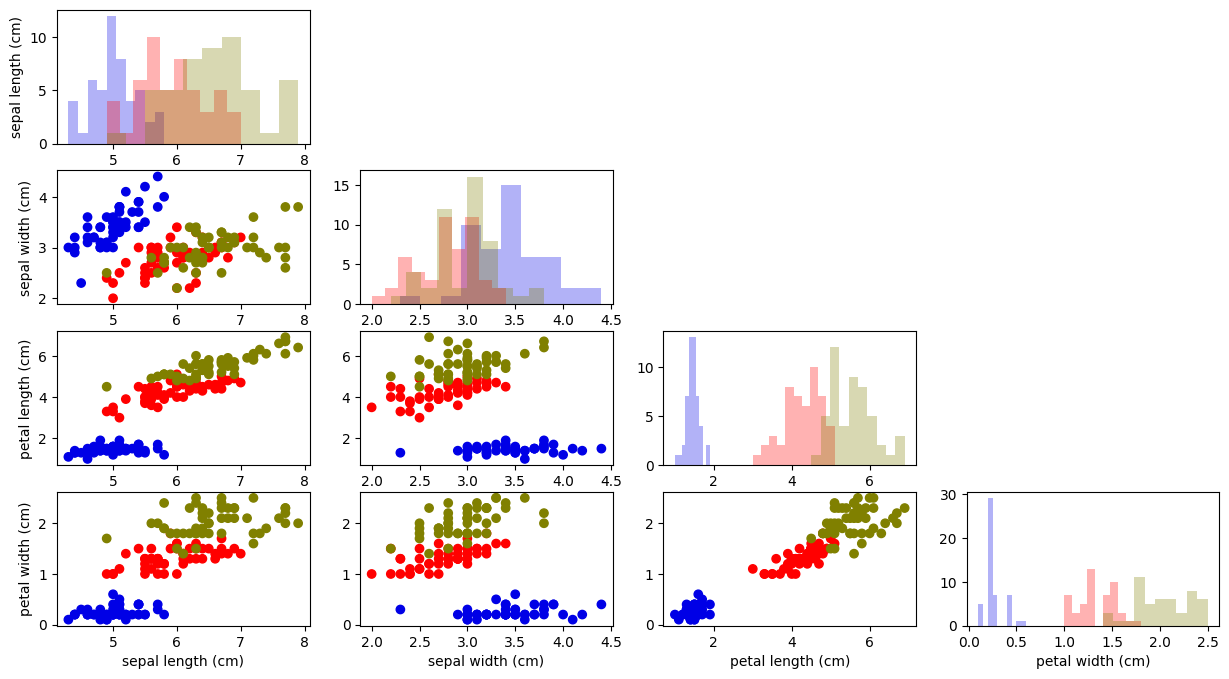

In [ ]:
import matplotlib
matplotlib.rcParams['figure.figsize']=(15,8)
from sklearn.datasets import load_iris
import matplotlib.pylab as plt

iris = load_iris()

color_map = {-1: (1, 1, 1), 0: (0, 0, .9), 1: (1, 0, 0), 2: (.5, .5, 0)}
colors = [color_map[y] for y in iris.target]

plt.figure(1)
for i, name_i in enumerate(iris['feature_names']):
    for j, name_j in enumerate(iris['feature_names']):

        if i>j:
            plt.subplot(4,4,i*4+j+1) # i numeruje wiersze, j kolumny
            plt.scatter(iris.data[:,j],iris.data[:,i],c = colors)

        elif i==j:
            plt.subplot(4,4,i*4+j+1) # i numeruje wiersze, j kolumny
            for k in range(3):
                plt.hist(iris.data[iris.target==k,j],color=color_map[k],alpha=0.3)
        if j ==0:
            plt.ylabel(name_i)
        if i ==3:
            plt.xlabel(name_j)
plt.show()

Dzielimy dane na zbiór treningowy i testowy:

In [ ]:
import numpy as np
from sklearn.model_selection import train_test_split

X = iris.data
Y = iris.target

X_train, X_test, y_train, y_test = train_test_split( X, Y, test_size=0.4, random_state=1)
print(X.shape, Y.shape)
print('-----')
print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)

(150, 4) (150,)
-----
(90, 4) (90,)
(60, 4) (60,)


Tworzymy klasyfikator i uczymy go na zbiorze treningowym a sprawdzmy na testowym:

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report

clf = LogisticRegression( multi_class='multinomial', solver ='lbfgs', max_iter= 1e4)

clf = LogisticRegression(random_state=42)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

print("Wyniki klasyfikacji dla niezbalansowanych danych:")
print("\nMacierz pomyłek:")
print(confusion_matrix(y_test, y_pred))
print("\nRaport klasyfikacji:")
print(classification_report(y_test, y_pred))

Wyniki klasyfikacji dla niezbalansowanych danych:

Macierz pomyłek:
[[19  0  0]
 [ 0 20  1]
 [ 0  1 19]]

Raport klasyfikacji:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        19
           1       0.95      0.95      0.95        21
           2       0.95      0.95      0.95        20

    accuracy                           0.97        60
   macro avg       0.97      0.97      0.97        60
weighted avg       0.97      0.97      0.97        60



### Jak interpretować raport klasyfikacji?

Raport klasyfikacji zawiera kilka kluczowych metryk dla każdej klasy:
- Precision: Jak wiele z przewidywanych przykładów danej klasy było poprawnych.
- Recall: Jak wiele z rzeczywistych przykładów danej klasy zostało poprawnie wykrytych.
- F1-score: Średnia harmoniczna precision i recall — dobry ogólny wskaźnik.

Średnie:
- Accuracy: 97% — ogólna skuteczność modelu.
- Macro avg: Średnia metryk dla każdej klasy (równa waga).
- Weighted avg: Średnia ważona względem liczby przykładów w każdej klasie.

Jak to jest liczone?
na przykadzie Precision:

Klasa 0:
$\frac{19}{19} =1.00$

Klasa 1:
$\frac{20}{20+1} = 0.95$

Klasa 2:
$\frac{19}{19+1}= 0.95$

Macro avg: $\frac{1.00+0.95+0.95}{3}= 0.97$

Weighted avg: uwzględnia liczbę przykładów (support) w każdej klasie:
$\frac{19⋅1.00+21⋅0.95+20⋅0.95}{60}=0.97$

## Porównywanie klasyfikatorów  na podstawie błędów generalizacji.
Najlepiej byłoby mieć możliwie mały błąd generalizacji — jak go oszacować?
Można zastosować następujące techniki:
* wiele zbiorów testowych:  trzeba mieć dużo danych, żeby wystarczyło na rozsądny zbiór treningowy i kilka testowych

* walidacja krzyżowa (_cross-validation_): najprostsza wersja (leave-one-out):
  * wybierz przypadek do odrzucenia
  * trenuj klasyfikator na wszystkich przypadkach oprócz tego jednego — na tym jednym oblicz błąd generalizacji
  * powtarzaj to dla każdego przypadku <br>Zaleta — można efektywnie użyć całego zbioru danych do uczenia i testowania, <br>Cena — wielokrotne uczenie modelu
 * inna wersja - walidacja k-krotna (*k-fold*)

 (ilustracja pochcodzi ze strony https://scikit-learn.org):


<img src="https://scikit-learn.org/stable/_images/grid_search_cross_validation.png">
  
UWAGA NA PRZECIEKI DANYCH: powinniśmy zapewnić, że w trakcie uczenia na danym podzbiorze nie ma żadnego dostępu do informacji mogącej wpływać na jakość klasyfikacji, a pochodzącej  podzbioru testowego.

Powysza  ilustracja pokazuje bardzo poglądowo i w "uporządkowany" sposób podział danych. Poniej zobaczmy jak w kodzie moze wyglądać podział danych na foldy:

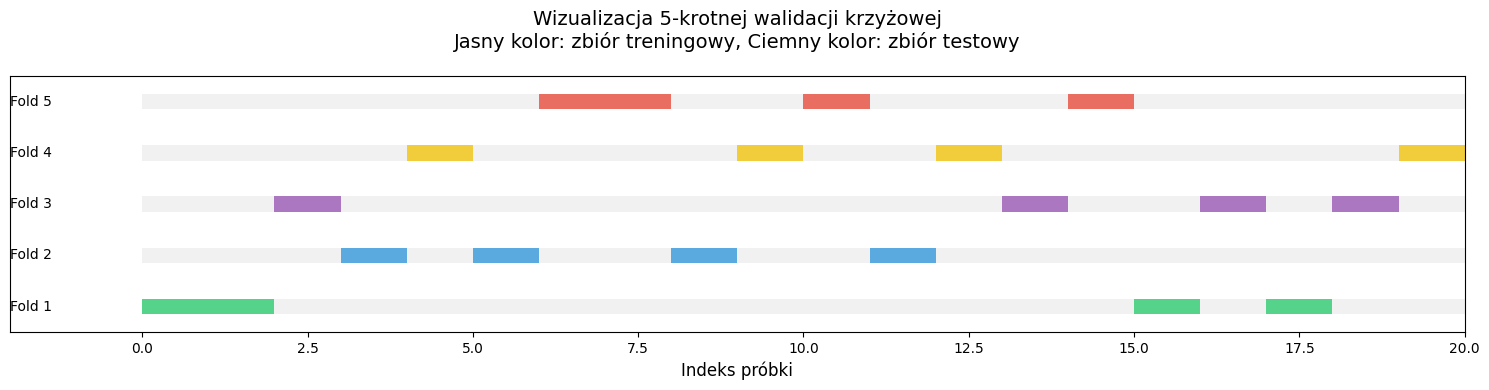

In [ ]:
import numpy as np
from sklearn.model_selection import KFold
import matplotlib.pyplot as plt

# Generujemy przykładowe dane
n_samples = 20
X = np.arange(n_samples)

# Tworzymy obiekt KFold
k_folds = 5
kf =   (n_splits=k_folds, shuffle=True, random_state=42)

# Przygotowujemy wizualizację
fig, ax = plt.subplots(figsize=(15, 4))
fold_colors = ['#2ecc71', '#3498db', '#9b59b6', '#f1c40f', '#e74c3c']

# Rysujemy paski dla każdego foldu
y_position = 0
for fold_id, (train_index, test_index) in enumerate(kf.split(X)):
    # Zaznaczamy zbiór treningowy
    ax.barh(y_position, len(X), left=0, height=0.3,
            color='lightgray', alpha=0.3, label='_nolegend_')

    # Zaznaczamy zbiór testowy
    test_positions = np.zeros(len(X))
    test_positions[test_index] = 1
    for i, is_test in enumerate(test_positions):
        if is_test:
            ax.barh(y_position, 1, left=i, height=0.3,
                   color=fold_colors[fold_id], alpha=0.8)

    ax.text(-2, y_position, f'Fold {fold_id+1}', va='center')
    y_position += 1

# Formatowanie wykresu
ax.set_xlim(-2, n_samples)
ax.set_ylim(-0.5, k_folds-0.5)
ax.set_xlabel('Indeks próbki', fontsize=12)
ax.set_title('Wizualizacja 5-krotnej walidacji krzyżowej\nJasny kolor: zbiór treningowy, Ciemny kolor: zbiór testowy',
             pad=20, fontsize=14)

# Usuwamy osie y
ax.set_yticks([])

plt.tight_layout()
plt.show()

Powyższa wizualizacja pokazuje jak dane są dzielone na zbiory treningowe i testowe w kolejnych foldach:

1. Cały zbiór danych jest podzielony na 5 równych części (foldów)
2. W każdej iteracji:
   * jedna część (zaznaczona ciemniejszym kolorem) służy jako zbiór testowy
   * pozostałe części (jaśniejszy kolor) tworzą zbiór treningowy
3. Proces jest powtarzany 5 razy, tak że każda próbka dokładnie raz znajdzie się w zbiorze testowym

Ta wizualizacja pomaga zrozumieć, że:
- każda próbka jest dokładnie raz używana do testowania
- zbiory testowe nie nakładają się na siebie
- wszystkie dane są efektywnie wykorzystywane zarówno do treningu jak i do testowania



## Przykład: porówniane modeli klasyfikujących irysy na podstawie różnych cech

Importujemy narzędzie do walidacji krzyżowej z sklearn

In [ ]:
from sklearn.model_selection import cross_val_score

Wybieramy różne podzbiory cech i wykonujemy na nich trening z walidacją krzyżową:

In [ ]:
sel_2 = [0,2]
X_train_sel =  X_train[:,sel_2]
scores = cross_val_score(clf, X_train_sel, y_train, cv=5, scoring='accuracy') # other scoring metrics: https://scikit-learn.org/stable/modules/model_evaluation.html#scoring-parameter
print(scores)
print('---')
print("dokładność %0.2f  +/- %0.2f" % (scores.mean(),  scores. np.sqrt(scores.size)))

[1.         0.94444444 0.94444444 0.94444444 0.94444444]
---
dokładność 0.96  +/- 0.01


In [ ]:
sel_3 = [2,3]
X_train_sel =  X_train[:,sel_3]
scores = cross_val_score(clf, X_train_sel, y_train, cv=5, scoring= 'accuracy') # other scoring metrics: https://scikit-learn.org/stable/modules/model_evaluation.html#scoring-parameter
print(scores)
print('---')
print("dokładność %0.2f  +/- %0.2f" % (scores.mean(),  scores.std(ddof=1)/np.sqrt(scores.size)))

[1.         0.94444444 0.88888889 0.94444444 0.94444444]
---
dokładność 0.94  +/- 0.02


In [ ]:
sel_4 = [0,3]
X_train_sel =  X_train[:,sel_4]
scores = cross_val_score(clf, X_train_sel, y_train, cv=5, scoring= 'accuracy') # other scoring metrics: https://scikit-learn.org/stable/modules/model_evaluation.html#scoring-parameter
print(scores)
print('---')
print("dokładność %0.2f  +/- %0.2f" % (scores.mean(),  scores.std(ddof=1)/np.sqrt(scores.size)))

[0.94444444 1.         0.94444444 0.83333333 0.83333333]
---
dokładność 0.91  +/- 0.03


W tym przykładzie najwyższą dokładnosć dostaliśmy dla sel_2. Trenujemy zatem model na wszystkich danych treningowych z cechami wg. sel_2

In [ ]:
sel = sel_2
clf.fit(X_train[:,sel], y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


Dokładność na zbiorze testowym:  0.9666666666666667
Macierz pomyłek dla zbioru testowego:
[[19  0  0]
 [ 0 20  1]
 [ 0  1 19]]


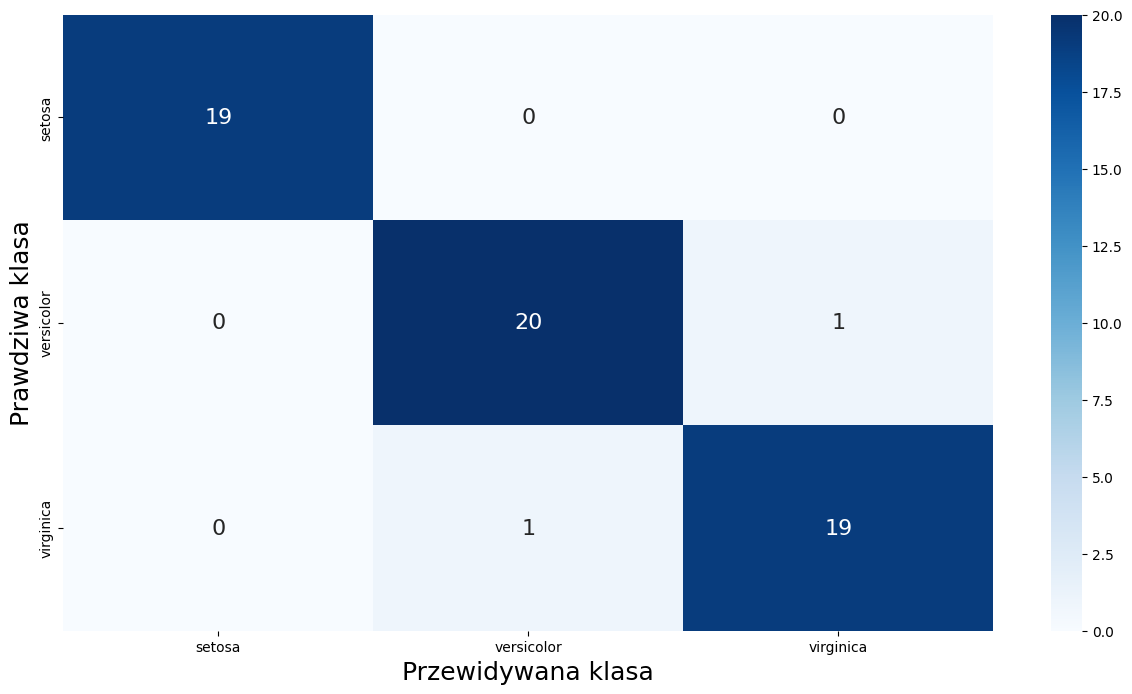

In [ ]:

from sklearn.metrics import accuracy_score #, ConfusionMatrixDisplay

sel = sel_2
y_pred = clf.predict(X_test[:, sel_2])

acc = accuracy_score(y_test, y_pred)
print('Dokładność na zbiorze testowym: ', acc)
print("Macierz pomyłek dla zbioru testowego:")

cf_matrix = confusion_matrix(y_test, y_pred)
print(cf_matrix)

import seaborn as sns
sns.heatmap(cf_matrix, annot=True,annot_kws={"fontsize":16},  cmap='Blues',xticklabels=iris.target_names,yticklabels=iris.target_names)
plt.ylabel('Prawdziwa klasa', fontsize=18)
plt.xlabel('Przewidywana klasa',fontsize=18 )
plt.show()

### A jak oszacować niepewność predykcji po dopasowaniu hyperparametrów?
Powyższa procedura doprowadziła nas do wybrania pewnego modelu i otrzymania jego finalnej wersji. Niestety nie mowi nam ona o niepewności klasyfikacji za jego pomocą.

### Zagnieżdżona walidacja krzyżowa

Zagnieżdżona walidacja krzyżowa (CV) jest często używana do trenowania modelu, w którym należy również zoptymalizować hiperparametry.
Zagnieżdżone CV szacuje błąd uogólnienia modelu bazowego i jego (hiper)parametry wyszukiwania.

- Wybór modelu bez zagnieżdżonego CV wykorzystuje te same dane do dostrojenia parametrów modelu i oceny jego wydajności.

- Informacje mogą zatem "wyciekać" do modelu i nadmiernie dopasowywać go do danych.

- Skala tego efektu zależy przede wszystkim od wielkości zbioru danych i stabilności modelu.
Analizę tych kwestii można znaleźć w artykule Cawley i Talbot (Cawley, G.C.; Talbot, N.L.C. On over-fitting in model selection and subsequent selection bias in performance evaluation. J. Mach. Learn. Res 2010,11, 2079-2107.)

Aby uniknąć tych problemów, zagnieżdżone CV wykorzystuje serię podziałów zbiorów na trenujące/walidacyjne/testowych i dwie pętle optymalizacyjne: wewnętrzna i zewnętrzną

- W wewnętrznej pętli ( wykonywanej np. przez GridSearchCV) wynik jest w przybliżeniu maksymalizowany poprzez dopasowanie modelu do każdego zbioru uczącego, a następnie bezpośrednio maksymalizowany przy wyborze (hiper)parametrów na zbiorze walidacyjnym.

- W zewnętrznej pętli (np. realizowanej przez cross_val_score) błąd uogólnienia jest szacowany poprzez uśrednienie wyników zestawu testowego w kilku podziałach zestawu danych.

Przykład takiej procedury zaczerpnięty z:
https://scikit-learn.org/stable/auto_examples/model_selection/plot_nested_cross_validation_iris.html#sphx-glr-auto-examples-model-selection-plot-nested-cross-validation-iris-py

In [ ]:
import numpy as np
from matplotlib import pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import GridSearchCV, KFold, cross_val_score
from sklearn.svm import SVC

# Load the dataset
iris = load_iris()
X_iris = iris.data
y_iris = iris.target

# Set up possible values of parameters to optimize over
p_grid = {"C": [1, 10, 100], "gamma": [0.01, 0.1]}

# We will use a Support Vector Classifier with "rbf" kernel
svm = SVC(kernel="rbf")
inner_cv=4
outer_cv=5
# Nested CV with parameter optimization
clf = GridSearchCV(estimator=svm, param_grid=p_grid, cv=inner_cv) # to wykonuje pętlę wewnętrzną
nested_score = cross_val_score(clf, X=X_iris, y=y_iris, cv=outer_cv) # tu wykonuje się pętla zewnętrzna
#nested_scores[i] = nested_score.mean()

print(nested_score)
print('---')
print("dokładność %0.2f  +/- %0.2f" % (nested_score.mean(), nested_score.std(ddof=1)/np.sqrt(nested_score.size)))

[0.96666667 1.         0.96666667 0.96666667 1.        ]
---
dokładność 0.98  +/- 0.01


### Jak skonfigurować model końcowy?

Ostateczny model jest konfigurowany i dopasowywany przy użyciu procedury zastosowanej w jednym przejściu pętli
zewnętrznej, np. pętli zewnętrznej zastosowanej do całego zbioru danych.

W następujący sposób:

- model jest wybierany na podstawie jego wydajności w zewnętrznej pętli zagnieżdżonej walidacji krzyżowej.
- Następnie procedura wewnętrzna jest stosowana do całego zbioru danych.
- Hiperparametry znalezione podczas tego końcowego wyszukiwania są następnie wykorzystywane do skonfigurowania
ostatecznego modelu.
- Ostateczny model jest dopasowywany do całego zbioru danych.



In [ ]:
from sklearn.model_selection import cross_val_predict
clf = GridSearchCV(estimator=svm, param_grid=p_grid, cv=inner_cv) # to wykonuje pętlę wewnętrzną
y_pred = cross_val_predict(clf, X=X_iris, y=y_iris, cv=outer_cv) # tu wykonuje się pętla zewnętrzna
print(y_pred)

cf_matrix = confusion_matrix(y_iris, y_pred)
print(cf_matrix)

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 1 1 1
 1 1 1 1 1 1 1 1 1 2 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 1 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2]
[[50  0  0]
 [ 0 48  2]
 [ 0  1 49]]


# Problem niezbalansowanych klas:

## Przykłady z rzeczywistych zastosowań:

1. **Diagnostyka medyczna**:
   * Wykrywanie nowotworów w obrazowaniu medycznym (np. mammografia)
     - Klasa większościowa: zdrowe przypadki (~98%)
     - Klasa mniejszościowa: przypadki nowotworowe (~2%)
   * Wykrywanie rzadkich chorób genetycznych
     - Klasa większościowa: typowy genotyp (>99%)
     - Klasa mniejszościowa: mutacja (<1%)

2. **Wykrywanie oszustw finansowych**:
   * Transakcje kartami kredytowymi
     - Klasa większościowa: uczciwe transakcje (~99.9%)
     - Klasa mniejszościowa: oszustwa (~0.1%)
   * Pranie pieniędzy
     - Klasa większościowa: legalne transakcje (>99%)
     - Klasa mniejszościowa: podejrzane transakcje (<1%)

3. **Awarie przemysłowe**:
   * Monitoring maszyn przemysłowych
     - Klasa większościowa: normalna praca (~95%)
     - Klasa mniejszościowa: stan awaryjny (~5%)
   * Kontrola jakości w produkcji
     - Klasa większościowa: produkty zgodne ze specyfikacją (~98%)
     - Klasa mniejszościowa: wadliwe produkty (~2%)

4. **Cyberbezpieczeństwo**:
   * Wykrywanie włamań sieciowych
     - Klasa większościowa: normalny ruch sieciowy (>99%)
     - Klasa mniejszościowa: ataki (<1%)
   * Filtrowanie spamu
     - Klasa większościowa: normalne wiadomości (~85%)
     - Klasa mniejszościowa: spam (~15%)

Te przykłady pokazują, że:
- Problem niezbalansowanych klas jest powszechny w praktycznych zastosowaniach
- Często klasa mniejszościowa jest tą bardziej interesującą (np. wykrywanie chorób, oszustw)
- Stopień niezbalansowania może być bardzo różny (od 15:85 do 0.1:99.9)
- Koszt błędnej klasyfikacji często jest asymetryczny (np. przeoczenie choroby vs fałszywy alarm)

## Źródła niezbalansowania:
- złe próbkowanie: prawdziwy rozkład klas w całej populacji jest w przybliżeniu równomierny, ale w zbiorze uczącym mamy dysproporcje
- rozkład klas w populacji faktycznie jest nierównomierny. Ten problem jest zwykle bardziej interesujący, w szczególności zwykle interesujące jest wykrywanie zjawisk rzadkich, np. diagnoza rzadko występującej choroby.

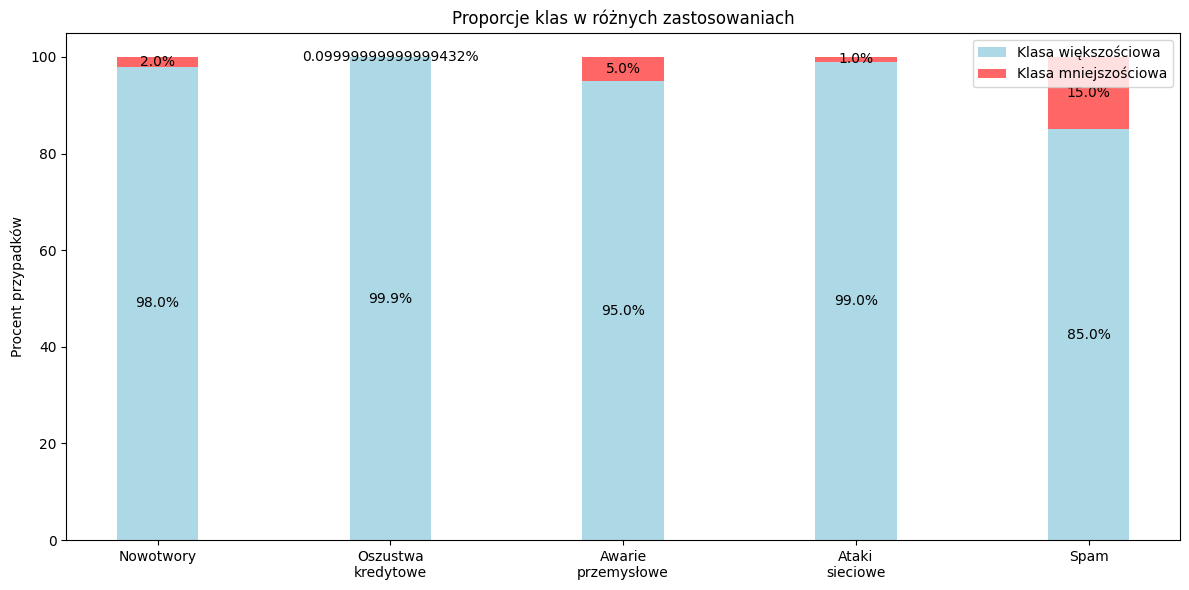

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Dane o proporcjach klas w różnych zastosowaniach
applications = ['Nowotwory', 'Oszustwa\nkredytowe', 'Awarie\nprzemysłowe', 'Ataki\nsieciowe', 'Spam']
majority = np.array([98, 99.9, 95, 99, 85])
minority = 100 - majority

# Tworzenie wykresu
fig, ax = plt.subplots(figsize=(12, 6))

# Tworzenie słupków
x = np.arange(len(applications))
width = 0.35

ax.bar(x, majority, width, label='Klasa większościowa', color='lightblue')
ax.bar(x, minority, width, bottom=majority, label='Klasa mniejszościowa', color='red', alpha=0.6)

# Dodawanie etykiet
ax.set_ylabel('Procent przypadków')
ax.set_title('Proporcje klas w różnych zastosowaniach')
ax.set_xticks(x)
ax.set_xticklabels(applications)
ax.legend()

# Dodawanie wartości procentowych na słupkach
for i in range(len(x)):
    # Dla klasy większościowej
    plt.text(x[i], majority[i]/2, f'{majority[i]}%', ha='center', va='center')
    # Dla klasy mniejszościowej
    plt.text(x[i], majority[i] + minority[i]/2, f'{minority[i]}%', ha='center', va='center')

plt.tight_layout()
plt.show()

## Możliwe strategie radzenia sobie z tym problemem
- zebrać więcej danych

## Strategie oceny modeli dla danych niezbalansowanych

1. **Metryki uwzględniające niezbalansowanie**:
   * Macierz pomyłek (confusion matrix)
     - Pokazuje szczegółowy rozkład błędów dla każdej klasy
     - Umożliwia wykrycie tendencyjności modelu
   
   * Współczynnik korelacji Matthews (MCC)
     - Uwzględnia wszystkie elementy macierzy pomyłek
     - Dobrze radzi sobie z różnymi stopniami niezbalansowania
     - Wartości od -1 (całkowita niezgodność) do +1 (idealna klasyfikacja)
   
   * Krzywa ROC i AUC
     - Niezależna od rozkładu klas
     - Pozwala na optymalizację progu decyzyjnego
     - Umożliwia balans między czułością a specyficznością
   
   * Precision-Recall Curve (PRC)
     - Szczególnie przydatna dla mocno niezbalansowanych danych
     - Pokazuje trade-off między precyzją a czułością
     - AUC-PR jest bardziej czuła na zmiany w klasie mniejszościowej niż ROC

## Strategie modyfikacji danych

1. **Metody próbkowania na poziomie danych**:

   a) **Oversampling (nadpróbkowanie klasy mniejszościowej)**:
      * Random Oversampling: losowe powielanie przykładów
      * SMOTE (Synthetic Minority Over-sampling Technique):
        - Generowanie syntetycznych przykładów
        - Tworzenie nowych próbek przez interpolację między istniejącymi
        - Warianty: Borderline-SMOTE, ADASYN
        - Praca źródłowa: https://arxiv.org/pdf/1106.1813.pdf . Pewną zletą algorytmu SMOTE jest to, że działa on w przestrzeni cech, nie wymagając wiedzy dziedzinowej do generacji nowych próbek. Idea tworzenia nowych próbek, cytując za autorami "Take the difference between the feature vector (sample) under consideration and its nearest neighbor. Multiply this difference by a random number between 0 and 1, and add it to the feature vector under consideration. This causes the selection of a random point along the line segment between two specific features." Jedna z implementacji: “UnbalancedDataset” module: https://github.com/scikit-learn-contrib/imbalanced-learn

   
   b) **Undersampling (podpróbkowanie klasy większościowej)**:
      * Random Undersampling: losowe usuwanie przykładów
      * Tomek Links: usuwanie przykładów granicznych
      * One-sided Selection:
        - Usuwanie przypadków redundantnych
        - Eliminacja przykładów granicznych
        - Usuwanie potencjalnie błędnie oznaczonych przypadków
      * NearMiss: różne strategie wyboru przykładów do usunięcia
   
   c) **Metody hybrydowe**:
      * SMOTEENN: SMOTE + Edited Nearest Neighbors
      * SMOTETomek: SMOTE + Tomek Links

2. **Metody na poziomie algorytmu**:

   a) **Modyfikacja funkcji kosztu**:
      * Ważenie klas (class weights)
      * Kary za błędną klasyfikację klasy mniejszościowej
      * Przykład: Weighted Random Forest, Cost-sensitive SVM
      * Przykład zmodyfikowanej funkcję kosztu, aby większa kara była przyznawana za błędną klasyfikację mniej licznej klasy (algorytmy typu penalized-SVM https://scikit-learn.org/stable/auto_examples/svm/plot_separating_hyperplane_unbalanced.html )
   
   b) **Ensemble Learning**:
      * Bagging z balansowaniem
      * Boosting z uwzględnieniem wag klas
      * EasyEnsemble, BalanceCascade

3. **Podejścia alternatywne**:

   a) **One-Class Learning**:
      * Modelowanie tylko klasy większościowej
      * Traktowanie klasy mniejszościowej jako anomalii
      * Przydatne gdy klasa mniejszościowa jest bardzo rzadka
   
   b) **Dekompozycja problemu**:
      * Hierarchiczne podejście do klasyfikacji
      * Osobne modele dla różnych aspektów problemu
      * Łączenie wyników w końcową decyzję

UWAGA: Wybór strategii zależy od:
- Stopnia niezbalansowania danych
- Rozmiaru zbioru danych
- Charakterystyki domeny problemowej
- Kosztu błędnej klasyfikacji
- Dostępnych zasobów obliczeniowych

## Przykład praktyczny: SMOTE i Tomek Links

Przykład ten pokazuje, że raczej wielkich cudów nie należy się spodziewać ;)

Zobaczmy jak działają techniki SMOTE i Tomek Links na przykładzie niezbalansowanego zbioru danych iris.
Najpierw stworzymy niezbalansowany zbiór danych poprzez usunięcie części przykładów z jednej z klas.

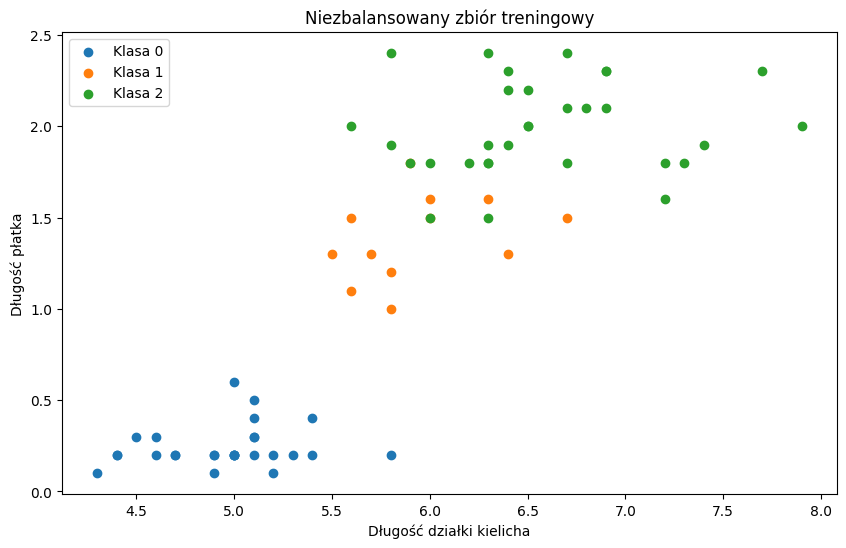

Rozkład klas: Counter({2: 31, 0: 27, 1: 12})

Wyniki klasyfikacji na niezbalansowanych danych:

Macierz pomyłek:
[[23  0  0]
 [ 0  4  1]
 [ 0  1 18]]

Raport klasyfikacji:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        23
           1       0.80      0.80      0.80         5
           2       0.95      0.95      0.95        19

    accuracy                           0.96        47
   macro avg       0.92      0.92      0.92        47
weighted avg       0.96      0.96      0.96        47



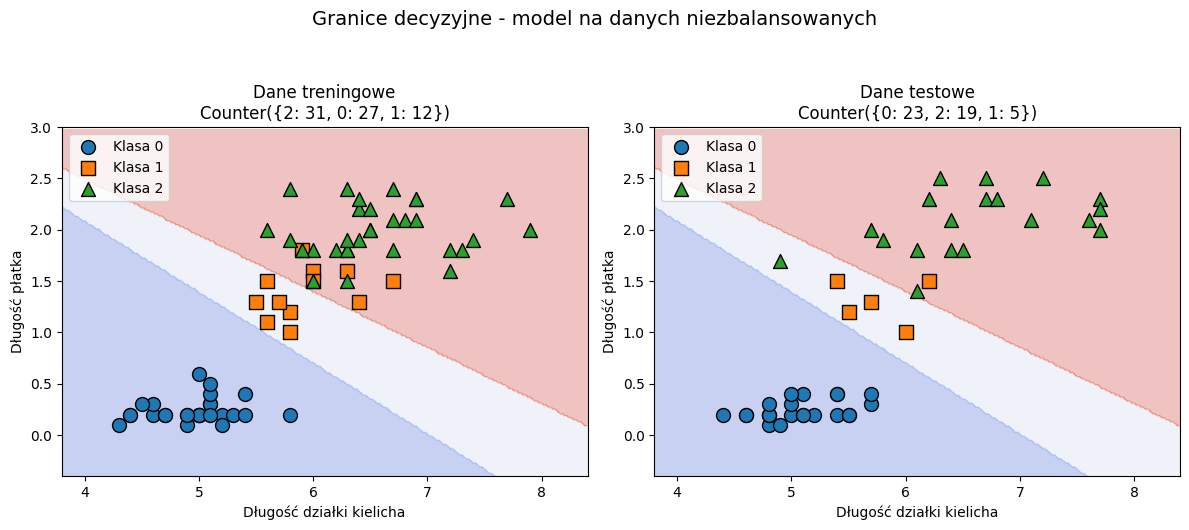

In [ ]:
import numpy as np
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from collections import Counter
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

# Wczytanie danych
iris = load_iris()
X = iris.data
y = iris.target

# Wybieramy tylko dwie cechy dla lepszej wizualizacji
X = X[:, [0, 3]]  # długość działki kielicha i długość płatka

# Tworzymy niezbalansowany zbiór danych - zostawiamy tylko 10 przykładów klasy 1
mask = np.ones(len(y), dtype=bool)
class1_indices = np.where(y == 1)[0]
remove_indices = np.random.choice(class1_indices, size=33, replace=False)
mask[remove_indices] = False
X_imb = X[mask]
y_imb = y[mask]

# Podział na zbiór treningowy i testowy
X_train, X_test, y_train, y_test = train_test_split(X_imb, y_imb, test_size=0.4, random_state=42)

# Funkcja do wizualizacji danych
def plot_data(X, y, title):
    plt.figure(figsize=(10, 6))
    for label in np.unique(y):
        mask = y == label
        plt.scatter(X[mask, 0], X[mask, 1], label=f'Klasa {label}')
    plt.xlabel('Długość działki kielicha')
    plt.ylabel('Długość płatka')
    plt.title(title)
    plt.legend()
    plt.show()
    print(f"Rozkład klas: {Counter(y)}")

# Wizualizacja oryginalnego zbioru danych
plot_data(X_train, y_train, "Niezbalansowany zbiór treningowy")

# Trenowanie modelu na niezbalansowanych danych
clf_imb = LogisticRegression(random_state=42)
clf_imb.fit(X_train, y_train)

# Predykcja i ocena
y_pred_imb = clf_imb.predict(X_test)

print("\nWyniki klasyfikacji na niezbalansowanych danych:")
print("\nMacierz pomyłek:")
print(confusion_matrix(y_test, y_pred_imb))
print("\nRaport klasyfikacji:")
print(classification_report(y_test, y_pred_imb))

# Wizualizacja granic decyzyjnych
def plot_decision_boundary(X_train, y_train, X_test, y_test, model, title):
    plt.figure(figsize=(12, 5))

    # Określenie globalnych granic dla obu wykresów
    x_min = min(X_train[:, 0].min(), X_test[:, 0].min()) - 0.5
    x_max = max(X_train[:, 0].max(), X_test[:, 0].max()) + 0.5
    y_min = min(X_train[:, 1].min(), X_test[:, 1].min()) - 0.5
    y_max = max(X_train[:, 1].max(), X_test[:, 1].max()) + 0.5

    # Dwa podwykresy: jeden dla danych treningowych, drugi dla testowych
    for idx, (X, y, subtitle) in enumerate([
        (X_train, y_train, 'Dane treningowe'),
        (X_test, y_test, 'Dane testowe')
    ]):
        plt.subplot(1, 2, idx + 1)

        # Tworzenie siatki punktów
        xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                            np.arange(y_min, y_max, 0.02))

        # Predykcja dla każdego punktu siatki
        Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
        Z = Z.reshape(xx.shape)

        # Rysowanie granic decyzyjnych
        plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')

        # Rysowanie punktów danych
        markers = ['o', 's', '^']  # różne markery dla różnych klas
        for label in np.unique(y):
            mask = y == label
            plt.scatter(X[mask, 0], X[mask, 1],
                       label=f'Klasa {label}',
                       marker=markers[label],
                       edgecolor='black',
                       s=100)

        plt.xlabel('Długość działki kielicha')
        plt.ylabel('Długość płatka')
        plt.title(f'{subtitle}\n{Counter(y)}')
        plt.legend()

        # Ustawienie tych samych zakresów dla obu wykresów
        plt.xlim(x_min, x_max)
        plt.ylim(y_min, y_max)

    plt.suptitle(title, y=1.05, fontsize=14)
    plt.tight_layout()
    plt.show()

# Wizualizacja granic decyzyjnych dla niezbalansowanego modelu
plot_decision_boundary(X_train, y_train, X_test, y_test, clf_imb,
                      "Granice decyzyjne - model na danych niezbalansowanych")

Teraz zastosujemy technikę SMOTE do wygenerowania syntetycznych przykładów klasy mniejszościowej:

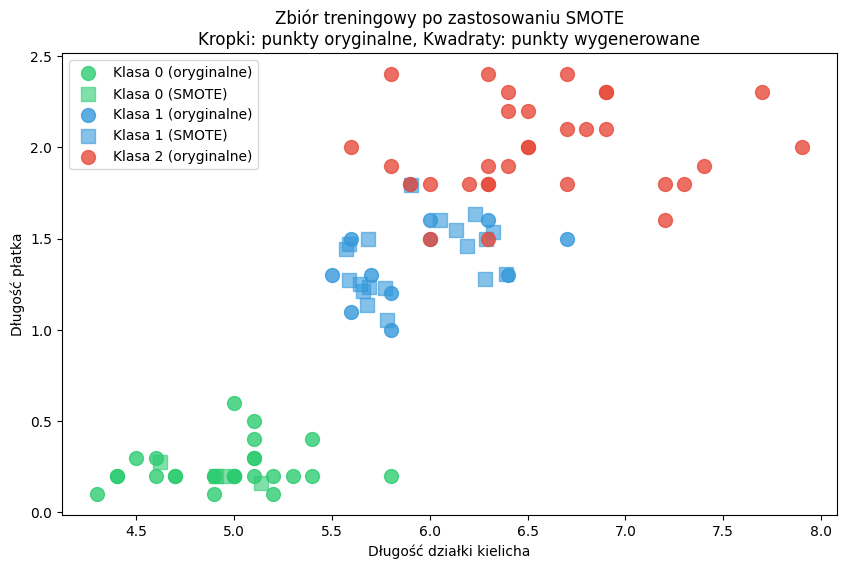


Rozkład klas w zbiorze po SMOTE:
Counter({0: 31, 1: 31, 2: 31})

Wyniki klasyfikacji po zastosowaniu SMOTE:

Macierz pomyłek:
[[23  0  0]
 [ 0  5  0]
 [ 0  2 17]]

Raport klasyfikacji:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        23
           1       0.71      1.00      0.83         5
           2       1.00      0.89      0.94        19

    accuracy                           0.96        47
   macro avg       0.90      0.96      0.93        47
weighted avg       0.97      0.96      0.96        47



In [ ]:
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import TomekLinks
from imblearn.pipeline import Pipeline

# Zastosowanie SMOTE i zachowanie informacji o oryginalnych punktach
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

# Zapamiętanie, które punkty są oryginalne
original_points = np.zeros(len(X_train_smote), dtype=bool)
for i, x in enumerate(X_train_smote):
    if any(np.all(x == x_orig) for x_orig in X_train):
        original_points[i] = True

# Wizualizacja danych po SMOTE z rozróżnieniem oryginalnych i wygenerowanych punktów
plt.figure(figsize=(10, 6))

# Definiowanie kolorów dla każdej klasy
colors = ['#2ecc71', '#3498db', '#e74c3c']  # zielony, niebieski, czerwony

for label in np.unique(y_train_smote):
    mask_orig = (y_train_smote == label) & original_points
    mask_synth = (y_train_smote == label) & ~original_points

    # Rysowanie oryginalnych punktów jako kropki
    if np.any(mask_orig):
        plt.scatter(X_train_smote[mask_orig, 0], X_train_smote[mask_orig, 1],
                   label=f'Klasa {label} (oryginalne)',
                   marker='o', s=100, alpha=0.8,
                   color=colors[label])

    # Rysowanie wygenerowanych punktów jako kwadraty
    if np.any(mask_synth):
        plt.scatter(X_train_smote[mask_synth, 0], X_train_smote[mask_synth, 1],
                   label=f'Klasa {label} (SMOTE)',
                   marker='s', s=100, alpha=0.6,
                   color=colors[label])

plt.xlabel('Długość działki kielicha')
plt.ylabel('Długość płatka')
plt.title("Zbiór treningowy po zastosowaniu SMOTE\nKropki: punkty oryginalne, Kwadraty: punkty wygenerowane")
plt.legend()
plt.show()

print("\nRozkład klas w zbiorze po SMOTE:")
print(Counter(y_train_smote))

# Trenowanie i ocena modelu na danych po SMOTE
clf_smote = LogisticRegression(random_state=42)
clf_smote.fit(X_train_smote, y_train_smote)
y_pred_smote = clf_smote.predict(X_test)

print("\nWyniki klasyfikacji po zastosowaniu SMOTE:")
print("\nMacierz pomyłek:")
print(confusion_matrix(y_test, y_pred_smote))
print("\nRaport klasyfikacji:")
print(classification_report(y_test, y_pred_smote))

Teraz zastosujemy technikę Tomek Links do usunięcia przykładów granicznych:

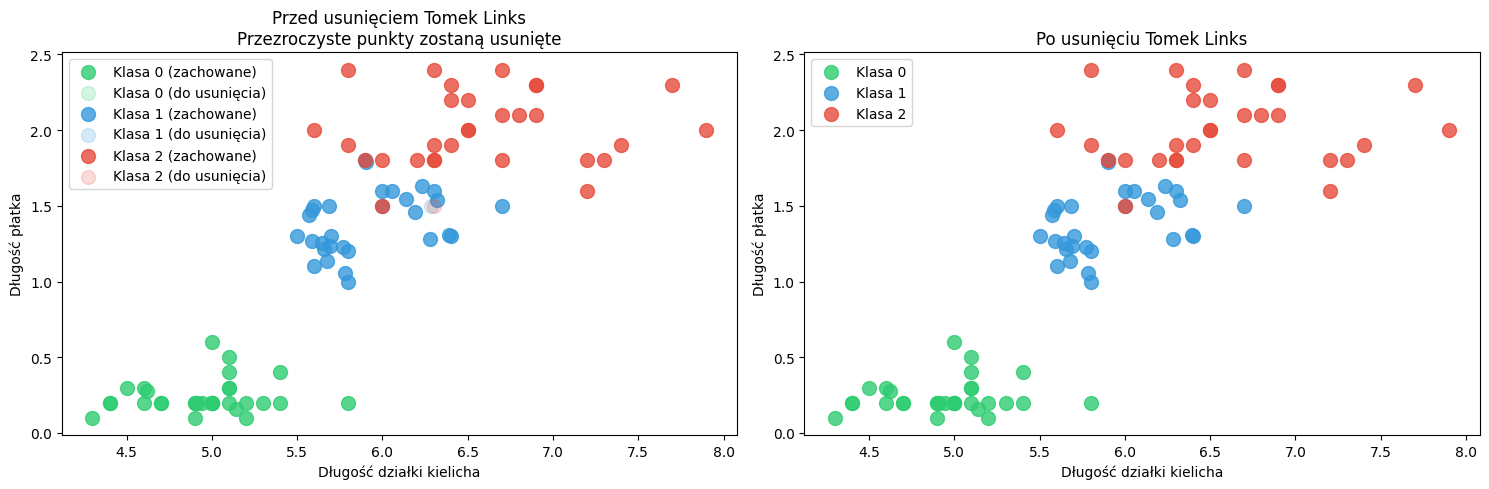


Liczba punktów usuniętych przez Tomek Links: 2
Rozkład klas po SMOTE + Tomek Links: Counter({0: 31, 1: 30, 2: 30})

Wyniki klasyfikacji po zastosowaniu SMOTE + Tomek Links:

Macierz pomyłek:
[[23  0  0]
 [ 0  5  0]
 [ 0  2 17]]

Raport klasyfikacji:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        23
           1       0.71      1.00      0.83         5
           2       1.00      0.89      0.94        19

    accuracy                           0.96        47
   macro avg       0.90      0.96      0.93        47
weighted avg       0.97      0.96      0.96        47



In [ ]:
# Zastosowanie SMOTE + Tomek Links
pipeline = Pipeline([
    ('smote', SMOTE(random_state=42)),
    ('tomek', TomekLinks())
])

# Zachowanie punktów po SMOTE, przed Tomek Links
X_smote, y_smote = SMOTE(random_state=42).fit_resample(X_train, y_train)

# Zastosowanie Tomek Links
X_combined, y_combined = pipeline.fit_resample(X_train, y_train)

# Identyfikacja punktów usuniętych przez Tomek Links
removed_points = np.zeros(len(X_smote), dtype=bool)
for i, x_smote in enumerate(X_smote):
    if not any(np.all(x_smote == x_comb) for x_comb in X_combined):
        removed_points[i] = True

# Wizualizacja procesu
plt.figure(figsize=(15, 5))

# Definiowanie kolorów dla każdej klasy
colors = ['#2ecc71', '#3498db', '#e74c3c']  # zielony, niebieski, czerwony

# 1. Dane po SMOTE z zaznaczonymi punktami do usunięcia
plt.subplot(1, 2, 1)
for label in np.unique(y_smote):
    mask = y_smote == label

    # Punkty, które zostaną zachowane
    mask_keep = mask & ~removed_points
    plt.scatter(X_smote[mask_keep, 0], X_smote[mask_keep, 1],
               color=colors[label], marker='o', s=100, alpha=0.8,
               label=f'Klasa {label} (zachowane)')

    # Punkty, które zostaną usunięte (bardziej przezroczyste)
    mask_remove = mask & removed_points
    plt.scatter(X_smote[mask_remove, 0], X_smote[mask_remove, 1],
               color=colors[label], marker='o', s=100, alpha=0.2,
               label=f'Klasa {label} (do usunięcia)')

plt.xlabel('Długość działki kielicha')
plt.ylabel('Długość płatka')
plt.title('Przed usunięciem Tomek Links\nPrzezroczyste punkty zostaną usunięte')
plt.legend()

# 2. Dane po zastosowaniu Tomek Links
plt.subplot(1, 2, 2)
for label in np.unique(y_combined):
    mask = y_combined == label
    plt.scatter(X_combined[mask, 0], X_combined[mask, 1],
               color=colors[label], marker='o', s=100, alpha=0.8,
               label=f'Klasa {label}')

plt.xlabel('Długość działki kielicha')
plt.ylabel('Długość płatka')
plt.title('Po usunięciu Tomek Links')
plt.legend()

plt.tight_layout()
plt.show()

print("\nLiczba punktów usuniętych przez Tomek Links:", sum(removed_points))
print("Rozkład klas po SMOTE + Tomek Links:", Counter(y_combined))

# Trenowanie i ocena modelu na danych po SMOTE + Tomek Links
clf_combined = LogisticRegression(random_state=42)
clf_combined.fit(X_combined, y_combined)
y_pred_combined = clf_combined.predict(X_test)

print("\nWyniki klasyfikacji po zastosowaniu SMOTE + Tomek Links:")
print("\nMacierz pomyłek:")
print(confusion_matrix(y_test, y_pred_combined))
print("\nRaport klasyfikacji:")
print(classification_report(y_test, y_pred_combined))

### Podsumowanie wyników

W powyższym przykładzie pokazaliśmy:

1. **Tworzenie niezbalansowanego zbioru danych**:
   - Usunęliśmy większość przykładów z klasy 1
   - Wizualizacja pokazuje nierównomierny rozkład klas

2. **Zastosowanie SMOTE**:
   - Generowanie syntetycznych przykładów klasy mniejszościowej
   - Wyrównanie liczebności klas
   - Wizualizacja pokazuje nowe, wygenerowane przykłady

3. **Zastosowanie Tomek Links po SMOTE**:
   - Usunięcie przykładów granicznych
   - Poprawa separacji między klasami
   - Potencjalne zmniejszenie szumu w danych

4. **Porównanie wyników**:
   - Macierze pomyłek pokazują różnice w klasyfikacji
   - Raport klasyfikacji dostarcza szczegółowych metryk dla każdej klasy
   - Widoczna poprawa w klasyfikacji klasy mniejszościowej

Te techniki są szczególnie przydatne gdy:
- Mamy mocno niezbalansowane klasy
- Zależy nam na dobrej klasyfikacji klasy mniejszościowej
- Potrzebujemy poprawić jakość granicy decyzyjnej

----
Dodatkowa lektura:

A Gentle Introduction to Imbalanced Classification:

https://machinelearningmastery.com/what-is-imbalanced-classification/

8 Tactics to Combat Imbalanced Classes in Your Machine Learning Dataset

https://machinelearningmastery.com/tactics-to-combat-imbalanced-classes-in-your-machine-learning-dataset/

Krawczyk, B. Learning from imbalanced data: open challenges and future directions. Prog Artif Intell 5, 221–232 (2016). https://doi.org/10.1007/s13748-016-0094-0:

https://link.springer.com/article/10.1007/s13748-016-0094-0

# Take Home Message - Podsumowanie wykładu

## 1. Krzywa ROC i AUC
- ROC (Receiver Operating Characteristic) pokazuje kompromis między czułością (TPR) a swoistością (1-FPR)
- AUC (Area Under Curve) to pojedyncza liczba określająca jakość klasyfikatora:
  * AUC = 1.0: idealny klasyfikator
  * AUC = 0.5: klasyfikator losowy
  * Im wyższe AUC, tym lepszy klasyfikator
- ROC jest szczególnie przydatna przy:
  * Porównywaniu różnych modeli
  * Ocenie klasyfikacji przy niezbalansowanych klasach
  * Wyborze optymalnego progu decyzyjnego

## 2. Kros-walidacja (Cross-validation)
- Technika oceny generalizacji modelu poprzez wielokrotny podział danych
- Zalety:
  * Dokładniejsza ocena jakości modelu
  * Redukcja wpływu losowego podziału na zbiór treningowy/testowy
  * Wykrywanie przeuczenia
- Podstawowe warianty:
  * k-fold cross-validation
  * Stratified k-fold (zachowuje proporcje klas)
  * Leave-one-out (szczególny przypadek k-fold gdzie k = n)
- Uwaga na przecieki danych

## 3. Problemy niezbalansowanych klas
- Wyzwania:
  * Standardowe metryki (np. accuracy) mogą być mylące
  * Model może ignorować klasę mniejszościową
- Rozwiązania:
  * SMOTE: generowanie syntetycznych przykładów klasy mniejszościowej
  * Tomek Links: czyszczenie granic między klasami
  * Dobór odpowiednich metryk (MCC, F1-score)
  * Modyfikacja wag klas w procesie uczenia

## 4. Najważniejsze wnioski praktyczne
1. **Ocena modelu**:
   - Zawsze używaj wielu metryk oceny
   - ROC/AUC dla całościowej oceny klasyfikatora
   - Kros-walidacja dla wiarygodnej oceny generalizacji

2. **Dobór danych**:
   - Zwracaj uwagę na balans klas
   - Stosuj techniki próbkowania gdy potrzebne (np. SMOTE, Tomek Links)
   - Waliduj jakość wygenerowanych/przetransformowanych danych

3. **Proces uczenia**:
   - Używaj stratified k-fold dla zachowania proporcji klas
   - Monitoruj wyniki na zbiorze walidacyjnym
   - Dostosowuj parametry modelu na podstawie wyników kros-walidacji
4. **Zwracaj uwagę na potencjalne przecieki danych/informacji**